In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    balanced_accuracy_score,
    roc_auc_score
)

In [2]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_data = tf.keras.utils.image_dataset_from_directory(
    "data",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    validation_split=0.2,
    subset="training",
    seed=42
)

validation_data = tf.keras.utils.image_dataset_from_directory(
    "data",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    validation_split=0.2,
    subset="validation",
    seed=42
)

Found 7021 files belonging to 4 classes.
Using 5617 files for training.
Found 7021 files belonging to 4 classes.
Using 1404 files for validation.


In [3]:
class_names = train_data.class_names
print("Classes :", class_names)

Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']


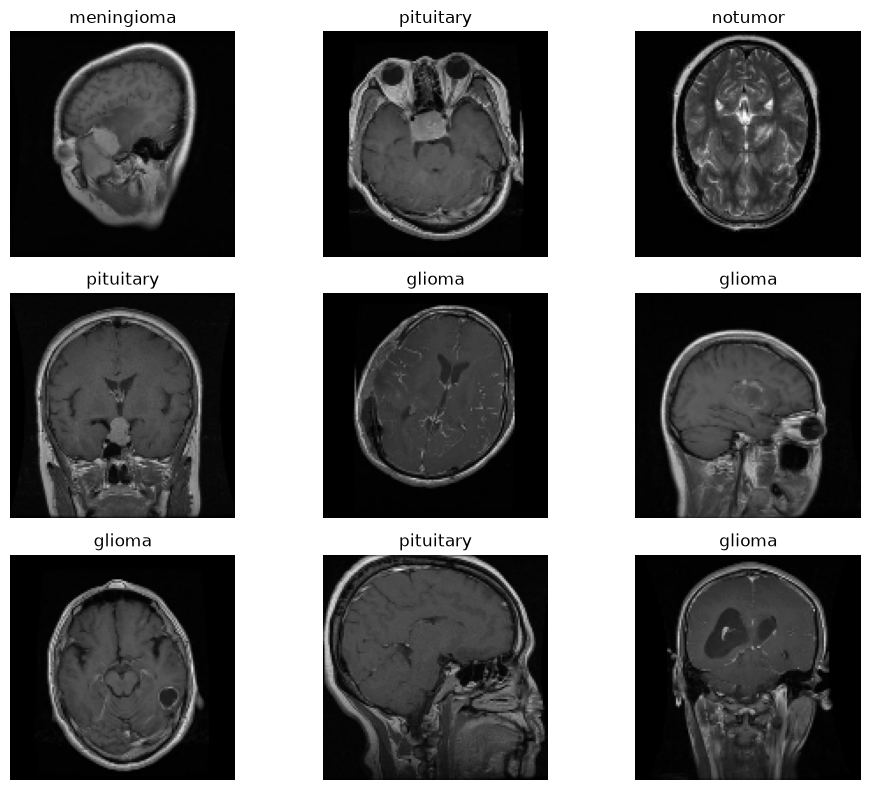

In [4]:
plt.figure(figsize=(10, 8))

for images, labels in train_data.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
for image_batch, labels_batch in train_data:
  print(image_batch.shape)
  print(labels_batch.shape)
  break

(32, 128, 128, 3)
(32,)


L' image_batch est un tenseur de la forme (32, 180, 180, 3) . Il s'agit d'un lot de 32 images de forme 180x180x3 (la dernière dimension fait référence aux canaux de couleur RVB). Le label_batch est un tenseur de la forme (32,) , ce sont des labels correspondants aux 32 images.

In [6]:
normalization_layer = tf.keras.layers.Rescaling(1./255)
normalized_train_data = train_data.map(lambda x, y: (normalization_layer(x), y))

In [7]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(128, 128, 3)),
    tf.keras.layers.Conv2D(16, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(
        len(class_names),
        activation="softmax"
    )
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,843,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,848,612 (7.05 MB)

 Trainable params: 1,848,612 (7.05 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    normalized_train_data,
    validation_data=validation_data.map(lambda x, y: (normalization_layer(x), y)),
    epochs=10,
    batch_size=BATCH_SIZE,
)

Epoch 1/10


c:\Users\youco\Desktop\live-coding-tensorflow-keras\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 68ms/step - accuracy: 0.7445 - loss: 0.6225 - val_accuracy: 0.8191 - val_loss: 0.4244
Epoch 2/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 64ms/step - accuracy: 0.9007 - loss: 0.2682 - val_accuracy: 0.8903 - val_loss: 0.2980
Epoch 3/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 65ms/step - accuracy: 0.9448 - loss: 0.1565 - val_accuracy: 0.8967 - val_loss: 0.2753
Epoch 4/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 12s 69ms/step - accuracy: 0.9703 - loss: 0.0905 - val_accuracy: 0.9288 - val_loss: 0.2105
Epoch 5/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 12s 70ms/step - accuracy: 0.9863 - loss: 0.0492 - val_accuracy: 0.9316 - val_loss: 0.2218
Epoch 6/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 71ms/step - accuracy: 0.9929 - loss: 0.0293 - val_accuracy: 0.9395 - val_loss: 0.2007
Epoch 7/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 71ms/step - accuracy: 0.9957 - loss: 0.0152 - val_accuracy: 0.9473 - val_loss: 0.1998
Epoch 8/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 12s 70ms/step - accuracy: 0.9955 - loss: 0.0144 - val_accurac

In [9]:
test_loss, test_accuracy = model.evaluate(validation_data.map(lambda x, y: (normalization_layer(x), y)))

print("Test loss :", test_loss)
print("Test accuracy :", test_accuracy)

44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9623 - loss: 0.1949
Test loss : 0.19493305683135986
Test accuracy : 0.9622507095336914


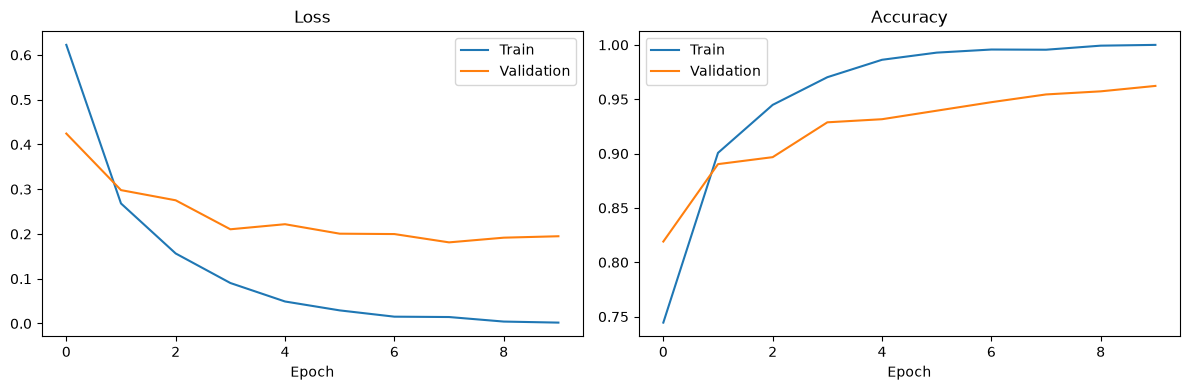

In [10]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

**Interprétation :**<br>
Overfitting : la loss d'entraînement diminue, mais celle de validation augmente.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


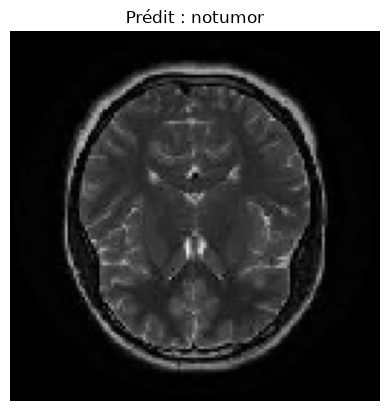

Classe réelle : notumor


In [ ]:
# 'glioma', 'meningioma', 'notumor', 'pituitary'
class_name = "notumor"
image = tf.keras.utils.load_img(
    "Tr-no_1594.jpg",
    # "Tr-pi_1456.jpg",
    target_size=IMG_SIZE
)
input_arr = tf.keras.utils.img_to_array(image)
batch_input_arr = np.array([input_arr])
probabilities = model.predict(batch_input_arr/255)
predicted_class = np.argmax(probabilities)

plt.imshow(input_arr.astype("uint8"))
plt.title(f"Prédit : {class_names[predicted_class]}")
plt.axis("off")
plt.show()

print("Classe réelle :", class_name)

In [22]:
# normalization_validation_data = validation_data.map(
#     lambda x, y: (normalization_layer(x), y)
# )

# y_true = np.concatenate([
#     labels.numpy()
#     for images, labels in validation_data
# ])

# y_prob = model.predict(
#     normalization_validation_data,
#     verbose=0
# )
# y_pred = np.argmax(y_prob, axis=1)

# precision = precision_score(
#     y_true, y_pred,
#     average="weighted",
#     zero_division=0
# )

# recall = recall_score(
#     y_true, y_pred,
#     average="weighted",
#     zero_division=0
# )

# f1 = f1_score(
#     y_true, y_pred,
#     average="weighted",
#     zero_division=0
# )

# balanced_acc = balanced_accuracy_score(y_true, y_pred)

# print(f"Precision weighted: {precision:.4f}")
# print(f"Recall weighted   : {recall:.4f}")
# print(f"F1-score weighted : {f1:.4f}")
# print(f"Balanced Accuracy : {balanced_acc:.4f}")

In [23]:
# cm = confusion_matrix(
#     y_true,
#     y_pred,
#     labels=np.arange(len(class_names))
# )

# plt.figure(figsize=(8, 6))
# sns.heatmap(
#     cm,
#     annot=True,
#     fmt="d",
#     cmap="Blues",
#     xticklabels=class_names,
#     yticklabels=class_names
# )

# plt.xlabel("Predicted class")
# plt.ylabel("Actual class")
# plt.title("Confusion Matrix")
# plt.tight_layout()
# plt.show()